In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones y duraciones normal y tope (semanas) se adjunta. Las actividades reducibles pueden acortarse hasta dos semanas, pero el coste no es lineal: la primera semana cuesta `ucr_1` k€ y la segunda `ucr_2` k€ (más cara: horas extra, turno de noche…). Las actividades con CUR infinito no pueden acelerarse.

In [4]:
pregunta_1 = "1. Calcule la duración normal del proyecto y sus rutas críticas.  "
pregunta_2 = "2. Reduzca el proyecto 3 semanas con mínimo coste aplicando Ackoff-Sasieni paso a paso con el *coste marginal*: el de la semana que toca acortar a cada actividad. Muestre en cada paso las rutas críticas, las opciones y su coste.  "
pregunta_3 = "3. ¿Qué habría resultado de aplicar el algoritmo con un CUR único por actividad igual a la media $(ucr_1 + ucr_2)/2$? Compare el coste real de esa solución con el del apartado anterior.  "
pregunta_4 = "4. ¿Por qué con costes crecientes por tramos el procedimiento semana a semana sigue siendo válido, y qué fallaría si la segunda semana fuera *más barata* que la primera?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Calcule la duración normal del proyecto y sus rutas críticas.  

2. Reduzca el proyecto 3 semanas con mínimo coste aplicando Ackoff-Sasieni paso a paso con el *coste marginal*: el de la semana que toca acortar a cada actividad. Muestre en cada paso las rutas críticas, las opciones y su coste.  

3. ¿Qué habría resultado de aplicar el algoritmo con un CUR único por actividad igual a la media $(ucr_1 + ucr_2)/2$? Compare el coste real de esa solución con el del apartado anterior.  

4. ¿Por qué con costes crecientes por tramos el procedimiento semana a semana sigue siendo válido, y qué fallaría si la segunda semana fuera *más barata* que la primera?  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, cap_duration, ucr_1 , ucr_2 
    ('A'     , '---'      , 6       , 4           , 4     , 7     ),
    ('B'     , '---'      , 8       , 8           , np.inf, np.inf),
    ('C'     , 'A,B'      , 4       , 4           , np.inf, np.inf),
    ('D'     , 'C'        , 6       , 4           , 1     , 5     ),
    ('E'     , 'A'        , 5       , 3           , 7     , 11    ),
    ('F'     , 'D'        , 5       , 5           , np.inf, np.inf),
    ('G'     , 'D'        , 5       , 3           , 5     , 11    ),
    ('H'     , 'G'        , 3       , 3           , np.inf, np.inf),
    ('I'     , 'E,F,H'    , 8       , 6           , 1     , 5     ),
], columns=['activity', 'predecessor', 'duration', 'cap_duration', 'ucr_1', 'ucr_2']).set_index('activity')
datos_enunciado

,predecessor,duration,cap_duration,ucr_1,ucr_2
activity,,,,,
A,---,6,4,4.0,7.0
B,---,8,8,inf,inf
C,"A,B",4,4,inf,inf
D,C,6,4,1.0,5.0
E,A,5,3,7.0,11.0
F,D,5,5,inf,inf
G,D,5,3,5.0,11.0
H,G,3,3,inf,inf
I,"E,F,H",8,6,1.0,5.0


El proyecto corresponde a la organización de un congreso científico; las actividades son las siguientes (las duraciones del cuadro están en semanas).

In [6]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Definición del programa y fechas',
    'B': 'Reserva de la sede',
    'C': 'Convocatoria de comunicaciones',
    'D': 'Página web e inscripciones',
    'E': 'Contratación de ponentes invitados',
    'F': 'Revisión de los trabajos recibidos',
    'G': 'Elaboración del programa definitivo',
    'H': 'Contratación de catering y viajes',
    'I': 'Edición del libro de actas',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Definición del programa y fechas
B,Reserva de la sede
C,Convocatoria de comunicaciones
D,Página web e inscripciones
E,Contratación de ponentes invitados
F,Revisión de los trabajos recibidos
G,Elaboración del programa definitivo
H,Contratación de catering y viajes
I,Edición del libro de actas


# Resolución

In [7]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
R = proyecto.path_matrix(dummies=False)
reduccion = 3

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Calcule la duración normal del proyecto y sus rutas críticas.  

In [ ]:
proyecto.display_roy_pasos(datos_proyecto['duration'])

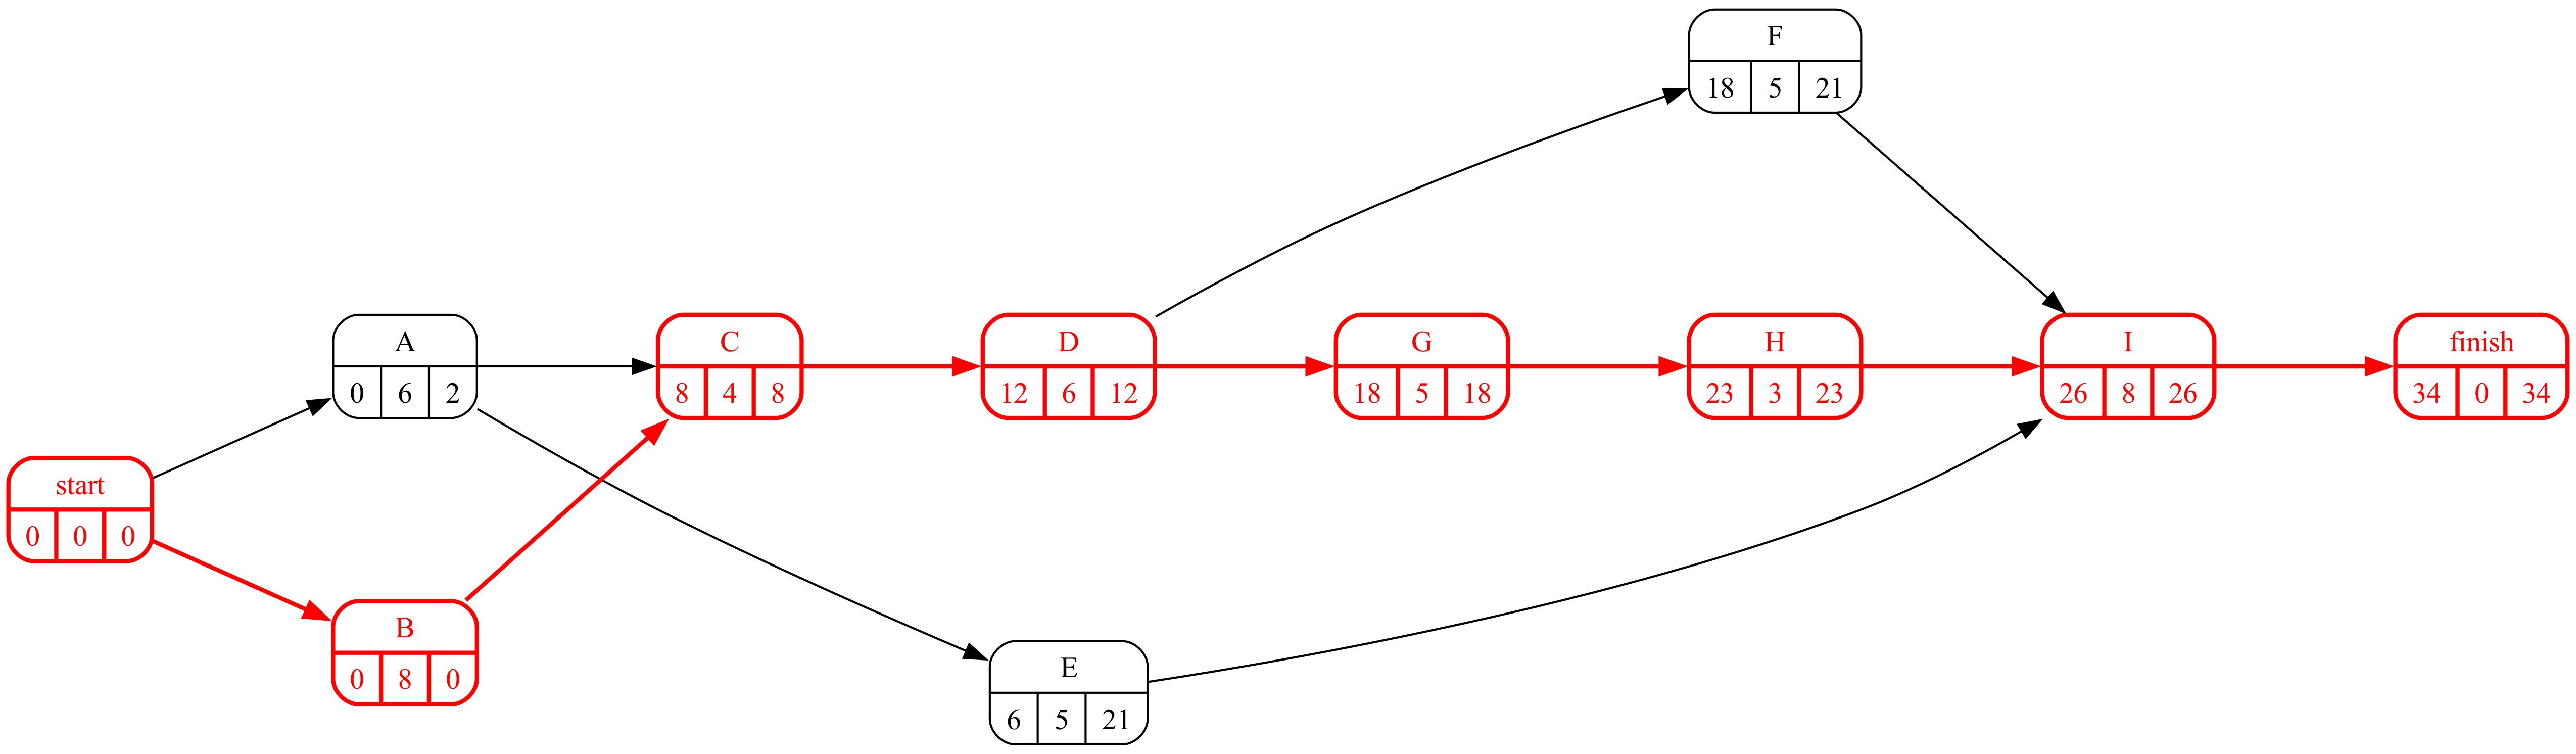

In [9]:
#| fig-cap: "Grafo Roy con las duraciones normales"
#| label: fig-pert
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

In [10]:
duracion_normal = proyecto.duration(datos_proyecto['duration'])
rutas_criticas = proyecto.critical_path(datos_proyecto['duration'])
for nombre, acts in rutas_criticas.items():
    print(f'{nombre}: {" - ".join(acts)}')
Markdown(f'Duración normal: {duracion_normal} semanas.')

Route_5: B - C - D - G - H - I


Duración normal: 34 semanas.

## Apartado 2

In [11]:
display(Markdown(pregunta_2))

2. Reduzca el proyecto 3 semanas con mínimo coste aplicando Ackoff-Sasieni paso a paso con el *coste marginal*: el de la semana que toca acortar a cada actividad. Muestre en cada paso las rutas críticas, las opciones y su coste.  

En cada paso el coste marginal de una actividad es `ucr_1` si aún no se ha acortado y `ucr_2` si ya se acortó una semana (infinito si no le queda margen). Las opciones son las actividades comunes a todas las rutas críticas y las parejas que cubren todas ellas; se elige la de menor coste marginal.

In [12]:
from itertools import combinations
def reducir_por_tramos(d0, tope, ucr_1, ucr_2, semanas):
    d = d0.astype(float).copy()
    filas = []
    for paso in range(1, semanas + 1):
        acortado = d0 - d
        marginal = pd.Series({a: (np.inf if d[a] <= tope[a] else (ucr_1[a] if acortado[a] == 0 else ucr_2[a])) for a in d.index})
        L = R @ d[R.columns]
        T = L.max(); criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        opciones = {}
        for a in set.intersection(*conjuntos):
            if marginal[a] < np.inf: opciones[a] = marginal[a]
        for p, q in combinations(sorted(set().union(*conjuntos)), 2):
            if marginal[p] < np.inf and marginal[q] < np.inf and all(p in s or q in s for s in conjuntos):
                opciones[f'{p}+{q}'] = marginal[p] + marginal[q]
        if not opciones:
            filas.append({'paso': paso, 'duración': int(T), 'rutas críticas': ', '.join(criticas), 'opciones (coste marginal)': 'ninguna', 'elegida': '—', 'coste': np.nan})
            break
        elegida = min(opciones, key=opciones.get)
        filas.append({'paso': paso, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste marginal)': '; '.join(f'{k} ({v:.0f})' for k, v in sorted(opciones.items(), key=lambda kv: kv[1])[:6]),
                      'elegida': elegida, 'coste': opciones[elegida]})
        for a in elegida.split('+'):
            d[a] -= 1
    return pd.DataFrame(filas).set_index('paso'), d
pasos_tramos, d_tramos = reducir_por_tramos(datos_proyecto['duration'], datos_proyecto['cap_duration'],
                                            datos_proyecto['ucr_1'], datos_proyecto['ucr_2'], reduccion)
pasos_tramos

,duración,rutas críticas,opciones (coste marginal),elegida,coste
paso,,,,,
1,34,Route_5,D (1); I (1); D+I (2); G (5); D+G (6); G+I (6),D,1.0
2,33,Route_5,I (1); D (5); G (5); D+I (6); G+I (6); D+G (10),I,1.0
3,32,Route_5,D (5); I (5); G (5); D+G (10); D+I (10); G+I (10),D,5.0


In [13]:
coste_tramos = float(pasos_tramos['coste'].sum())
acortadas = (datos_proyecto['duration'] - d_tramos)
Markdown(f'Se acortan {", ".join(f"{a} ({int(x)})" for a, x in acortadas[acortadas > 0].items())}; duración {proyecto.duration(d_tramos.astype(int))} semanas; sobrecoste {coste_tramos:.0f} k€.')

Se acortan D (2), I (1); duración 31 semanas; sobrecoste 7 k€.

## Apartado 3

In [14]:
display(Markdown(pregunta_3))

3. ¿Qué habría resultado de aplicar el algoritmo con un CUR único por actividad igual a la media $(ucr_1 + ucr_2)/2$? Compare el coste real de esa solución con el del apartado anterior.  

In [15]:
ucr_medio = ((datos_proyecto['ucr_1'] + datos_proyecto['ucr_2']) / 2)
tabla_ackoff, pasos, d_medio, _ = proyecto.ackoff(durations=datos_proyecto['duration'], min_durations=datos_proyecto['cap_duration'],
                                                  costs=ucr_medio, reduction=reduccion, report=False)
acortadas_medio = (datos_proyecto['duration'] - d_medio.reindex(datos_proyecto.index)).astype(int)
def coste_real(acortadas):
    return float(sum((datos_proyecto.loc[a, 'ucr_1'] if x >= 1 else 0) + (datos_proyecto.loc[a, 'ucr_2'] if x >= 2 else 0) for a, x in acortadas.items()))
pd.DataFrame({'con coste marginal': [', '.join(f'{a} ({int(x)})' for a, x in acortadas[acortadas > 0].items()), coste_tramos],
              'con CUR medio': [', '.join(f'{a} ({int(x)})' for a, x in acortadas_medio[acortadas_medio > 0].items()), coste_real(acortadas_medio)]},
             index=['actividades acortadas', 'coste real (k€)'])

,con coste marginal,con CUR medio
actividades acortadas,"D (2), I (1)","D (2), I (1)"
coste real (k€),7.0,7.0


Con el CUR medio el algoritmo puede preferir acortar dos semanas una actividad que parece barata «de media» cuando en realidad su segunda semana es cara, o evitar una cuya primera semana era la más barata de todas. El coste real se obtiene valorando cada semana con su tramo.

## Apartado 4

In [16]:
display(Markdown(pregunta_4))

4. ¿Por qué con costes crecientes por tramos el procedimiento semana a semana sigue siendo válido, y qué fallaría si la segunda semana fuera *más barata* que la primera?  

Con costes marginales *crecientes* la función de coste de cada actividad es convexa, y en ese caso acortar semana a semana eligiendo siempre la opción marginal más barata es óptimo (es la misma razón por la que el CUR constante funciona). Si la segunda semana fuera más barata que la primera (coste cóncavo: un coste fijo de movilización y luego barato), el paso a paso fallaría: la primera semana parecería cara y nunca se emprendería, aunque acortar dos de golpe fuera lo mejor; habría que evaluar las dos semanas juntas.